# Exploring the Olist data before modelling

Every design decision in this repository leans on a claim about the data.
This notebook checks those claims directly on the raw tables:

1. How large is the dataset and what period does it cover?
2. The identity trap: what exactly is a customer here?
3. How rare is a repeat purchase, really?
4. How often are deliveries late, and by how much?
5. How do review scores behave, and how do they relate to delivery?

It reads whatever sits in `data/raw`: the real Kaggle download locally, or
the synthetic fixture data in CI (same schema, same quirks, smaller).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def find_repo_root() -> Path:
    current = Path.cwd()
    for candidate in (current, *current.parents):
        if (candidate / "conf" / "pipeline.yaml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the repository")


ROOT = find_repo_root()
RAW = ROOT / "data" / "raw"

orders = pd.read_csv(
    RAW / "olist_orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
)
customers = pd.read_csv(RAW / "olist_customers_dataset.csv")
reviews = pd.read_csv(RAW / "olist_order_reviews_dataset.csv")
payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
# This file starts with a UTF-8 byte order mark; utf-8-sig strips it.
translation = pd.read_csv(RAW / "product_category_name_translation.csv", encoding="utf-8-sig")

print(
    f"orders {len(orders):,} | customers {len(customers):,} | "
    f"reviews {len(reviews):,} | payments {len(payments):,}"
)
print(
    "purchase span:",
    orders.order_purchase_timestamp.min().date(),
    "to",
    orders.order_purchase_timestamp.max().date(),
)

orders 99,441 | customers 99,441 | reviews 99,224 | payments 103,886
purchase span: 2016-09-04 to 2018-10-17


## The identity trap

Olist issues a fresh `customer_id` for every order. The person behind the
orders is `customer_unique_id`. Joining on the wrong one silently turns
customer-level analysis into order-level analysis, which is why the
pipeline treats this as a validated contract rather than trivia.

customer_id values:        99,441
customer_unique_id values: 96,096


customers with a second order ever: 3.12%


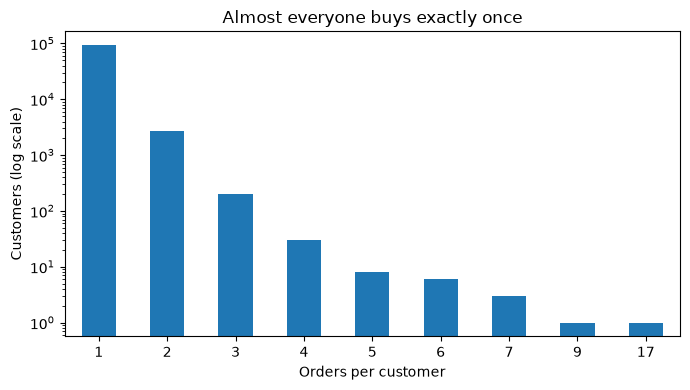

In [2]:
merged = orders.merge(customers, on="customer_id", how="left")
n_ids = customers["customer_id"].nunique()
n_people = customers["customer_unique_id"].nunique()
print(f"customer_id values:        {n_ids:,}")
print(f"customer_unique_id values: {n_people:,}")

orders_per_person = merged.groupby("customer_unique_id")["order_id"].count()
distribution = orders_per_person.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
distribution.plot(kind="bar", ax=ax, rot=0)
ax.set_yscale("log")
ax.set_xlabel("Orders per customer")
ax.set_ylabel("Customers (log scale)")
ax.set_title("Almost everyone buys exactly once")
plt.tight_layout()

repeat_share = (orders_per_person >= 2).mean()
print(f"customers with a second order ever: {repeat_share:.2%}")

The repeat share above is the all-time number. The modelling label is
stricter (a further purchase within 180 days of a cutoff date), so the
class the models chase is rarer still, around one percent. Two design
consequences:

* accuracy and even ROC-AUC flatter models here; precision-recall and
  targeting metrics are the informative view, and
* for time-to-event questions, customers without a second purchase are
  right-censored rather than churned, which is the survival analysis job.

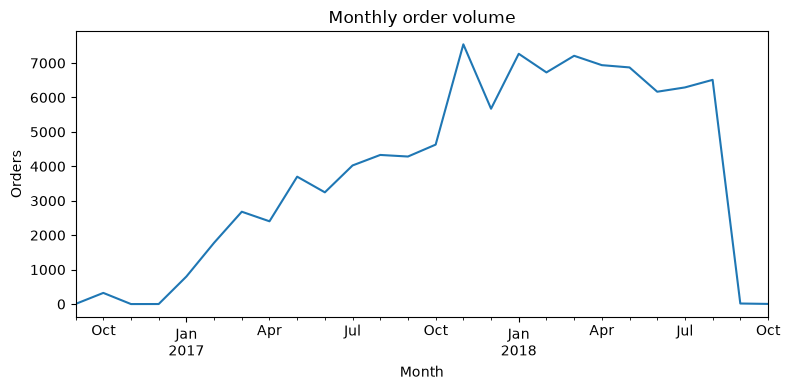

In [3]:
monthly = orders.set_index("order_purchase_timestamp").resample("MS")["order_id"].count()
fig, ax = plt.subplots(figsize=(8, 4))
monthly.plot(ax=ax)
ax.set_xlabel("Month")
ax.set_ylabel("Orders")
ax.set_title("Monthly order volume")
plt.tight_layout()

## Delivery performance

The delay is measured against the estimate shown at checkout
(`order_estimated_delivery_date`, always a midnight timestamp). Negative
values are early deliveries.

late deliveries: 6.77%
median transit: 10 days


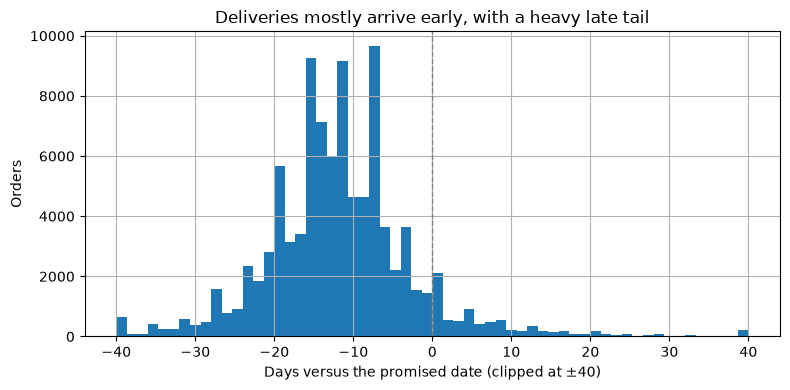

In [4]:
delivered = orders[orders.order_delivered_customer_date.notna()].copy()
delivered["delay_days"] = (
    delivered.order_delivered_customer_date - delivered.order_estimated_delivery_date
).dt.days
delivered["transit_days"] = (
    delivered.order_delivered_customer_date - delivered.order_purchase_timestamp
).dt.days

fig, ax = plt.subplots(figsize=(8, 4))
delivered["delay_days"].clip(-40, 40).hist(bins=60, ax=ax)
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Days versus the promised date (clipped at ±40)")
ax.set_ylabel("Orders")
ax.set_title("Deliveries mostly arrive early, with a heavy late tail")
plt.tight_layout()

late_rate = (delivered["delay_days"] > 0).mean()
print(f"late deliveries: {late_rate:.2%}")
print(f"median transit: {delivered['transit_days'].median():.0f} days")

## Reviews and how delivery shapes them

orders with a review: 99.3%
reviews with free text: 40.3%
On time    4.29
Late       2.27
Name: review_score, dtype: float64


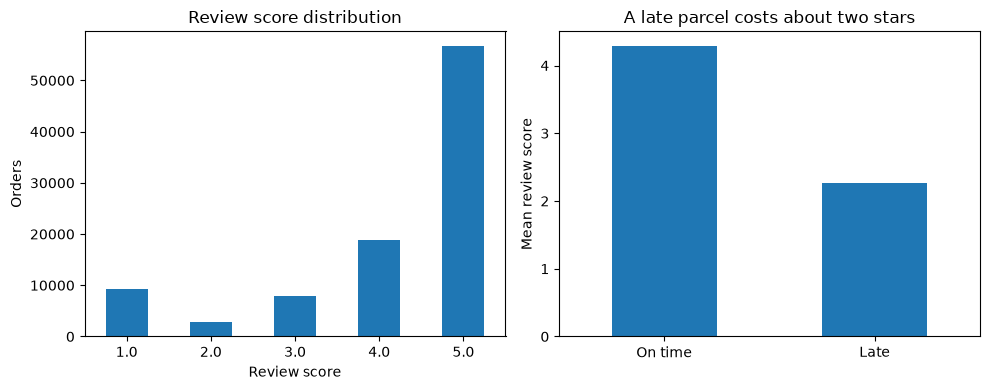

In [5]:
latest_review = reviews.sort_values(["order_id", "review_creation_date"]).drop_duplicates(
    "order_id", keep="last"
)
scored = delivered.merge(
    latest_review[["order_id", "review_score", "review_comment_message"]],
    on="order_id",
    how="left",
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
scored["review_score"].value_counts().sort_index().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_xlabel("Review score")
axes[0].set_ylabel("Orders")
axes[0].set_title("Review score distribution")

by_lateness = scored.groupby(scored["delay_days"] > 0)["review_score"].mean()
by_lateness.index = ["On time", "Late"]
by_lateness.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_ylabel("Mean review score")
axes[1].set_title("A late parcel costs about two stars")
plt.tight_layout()

print(f"orders with a review: {scored['review_score'].notna().mean():.1%}")
print(f"reviews with free text: {scored['review_comment_message'].notna().mean():.1%}")
print(by_lateness.round(2))

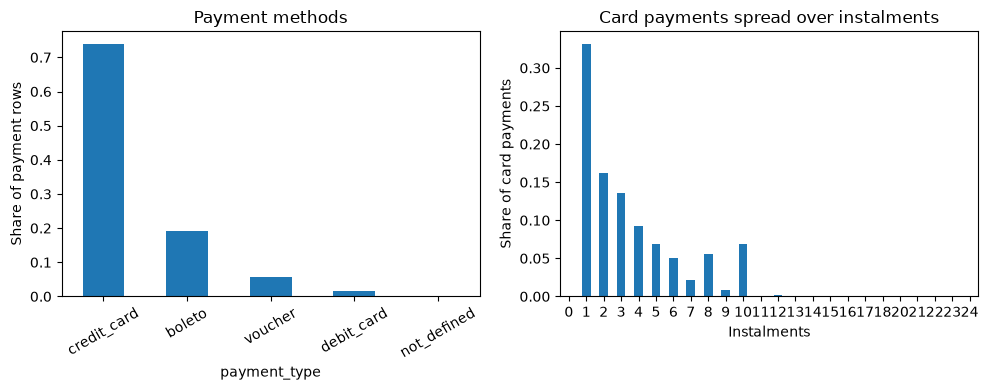

In [6]:
mix = payments["payment_type"].value_counts(normalize=True)
installments = (
    payments.loc[payments.payment_type == "credit_card", "payment_installments"]
    .value_counts(normalize=True)
    .sort_index()
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
mix.plot(kind="bar", ax=axes[0], rot=30)
axes[0].set_ylabel("Share of payment rows")
axes[0].set_title("Payment methods")
installments.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_xlabel("Instalments")
axes[1].set_ylabel("Share of card payments")
axes[1].set_title("Card payments spread over instalments")
plt.tight_layout()

## What this changes about the design

* **Grain.** Every join goes through `customer_unique_id`; the per-order
  `customer_id` is a foreign key, not an identity.
* **Imbalance.** Repeat purchase within a fixed horizon sits around one
  percent, so the headline metric is precision-recall and lift at a
  targeting depth, with class weighting during training.
* **Censoring.** Most customers have simply not repurchased yet by the end
  of the window. The survival analysis treats them as right-censored,
  which is the statistically sound reading.
* **Delivery matters.** Late deliveries are common enough to model and
  clearly associated with worse reviews, motivating both features and the
  delivery experiment in the A/B design.
* **Timing.** Estimates are midnight-dated, reviews arrive days after
  delivery, and some orders deliver after the feature cutoff; the feature
  builder only uses what was knowable on the cutoff date.